# Figures C1 and C2: Denmark Strait freshwater transport timeseries and sensitivities for varying reference salinity

This notebook will reproduce Figures C1 and C2 from  E. Boland et al. 2026 (doi to come). This requires input datafiles from the ECCOv4 solution - please see the README for details.

The freshwater transport is derived from the combination of the volume and salt transports.

The datafiles were created as follows:
- m_horflux_vol_denm.* and m_horflux_salt_denm.*, found in {EXPDIR}/fwd_26y,
  are generated by re-running the ECCOv4r4 solution, using the Denmark Strait mask created by running generate_masks
- Sensitivity fields adxx_*, in {EXPDIR}/ad_10y_denstr_horflux_vol and {EXPDIR}/ad_10y_denstr_horflux_salt_Dec, were generated by running adjoint sensitivity experiments as described in Boland et al. 2026.

Please attribute any plots or code from this notebook using the DOI from Zenodo: https://doi.org/10.5281/zenodo.17225514

E Boland Oct 2026 [emmomp@bas.ac.uk](email:emmomp@bas.ac.uk)

In [15]:
import xarray as xr
from matplotlib import pyplot as plt
%matplotlib inline
import sys
sys.path.insert(0,'/users/emmomp/Python/ECCOv4-py')
import ecco_v4_py as ecco
sys.path.insert(0,'/users/emmomp/Python')
import xadjoint as xad
import utils as ut
from inputs import GRIDDIR, EXPDIR

In [16]:
srefs=[34.8,35,35.2]

In [19]:
volfc=ut.get_soln('horflux_vol_denm',f'{EXPDIR}/fwd_26y/')
vol_climanom,vol_mth=ut.soln_anoms(volfc)
saltfc=ut.get_soln('horflux_salt_denm',f'{EXPDIR}/fwd_26y/')
salt_climanom,salt_mth=ut.soln_anoms(saltfc)

read_llc_to_tiles: full_filename:  /users/emmomp/data/canari/experiments/fwd_26y//m_horflux_vol_denm.0000000129.data
read_llc_to_tiles: full_filename:  /users/emmomp/data/canari/experiments/fwd_26y//m_horflux_salt_denm.0000000129.data


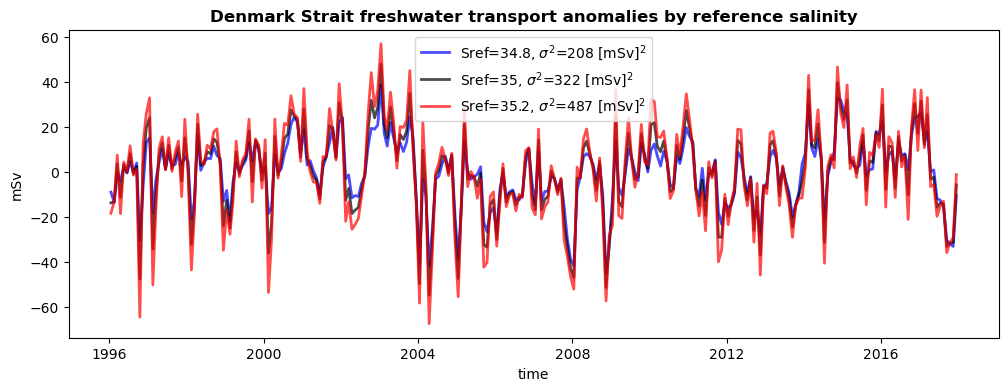

In [32]:
colors=['b','k','r']
plt.figure(figsize=[12,4])
for iis,sref in enumerate(srefs):
    fw=((vol_climanom-salt_climanom/sref))/1e3
    fwvar=fw.var()
    (fw).plot(alpha=0.7,color=colors[iis],label=f'Sref={sref}, $\sigma^2$={fwvar:3.0f} [mSv]$^2$', linewidth=2)
plt.legend()
plt.title('Denmark Strait freshwater transport anomalies by reference salinity',fontweight='bold')
plt.ylabel('mSv')
plt.savefig('../plots/FigC1_denstr_fwtransport_bysref.pdf',bbox_inches='tight')

In [24]:
lag0=['2005-12-31','2005-06-30']
of=['Vol_Dec','Salt_Dec']
expts=['ad_10y_denstr_horflux_vol','ad_10y_denstr_horflux_salt_Dec']
year=2005
startdate='1996-01-01'

In [25]:
ds_all=[]
for ie,expt in enumerate(expts):
    print(expt)
    myexp = xad.Experiment(GRIDDIR,f"{EXPDIR}/{expt}",start_date=startdate,lag0=lag0[ie])
    myexp.load_vars(['adxx_qnet','adxx_tauu','adxx_tauv','adxx_empmr'])

    myexp.data['adxx_tauu']=-myexp.data['adxx_tauu'].rename({'i_g':'i'})
    myexp.data['adxx_tauv']=-myexp.data['adxx_tauv'].rename({'j_g':'j'})
    
    myexp.data=myexp.data.assign_coords({'exp':of[ie]})
    ds_all.append(myexp.data)
ds_all=xr.concat(ds_all,'exp')

ad_10y_denstr_horflux_vol
Loading adjoint dict
Found 26 ADJ variables
Found 12 adxx variables
Reading in adxx_qnet
Reading in adxx_tauu
Reading in adxx_tauv
Reading in adxx_empmr
ad_10y_denstr_horflux_salt_Dec
Loading adjoint dict
Found 6 ADJ variables
Found 7 adxx variables
Reading in adxx_qnet
Reading in adxx_tauu
Reading in adxx_tauv
Reading in adxx_empmr


In [27]:
ds_FWapprox={}
for iis,sref in enumerate(srefs):
    ds_FWapprox[sref]=(ds_all.sel(exp='Vol_Dec')-ds_all.sel(exp='Salt_Dec')/sref)

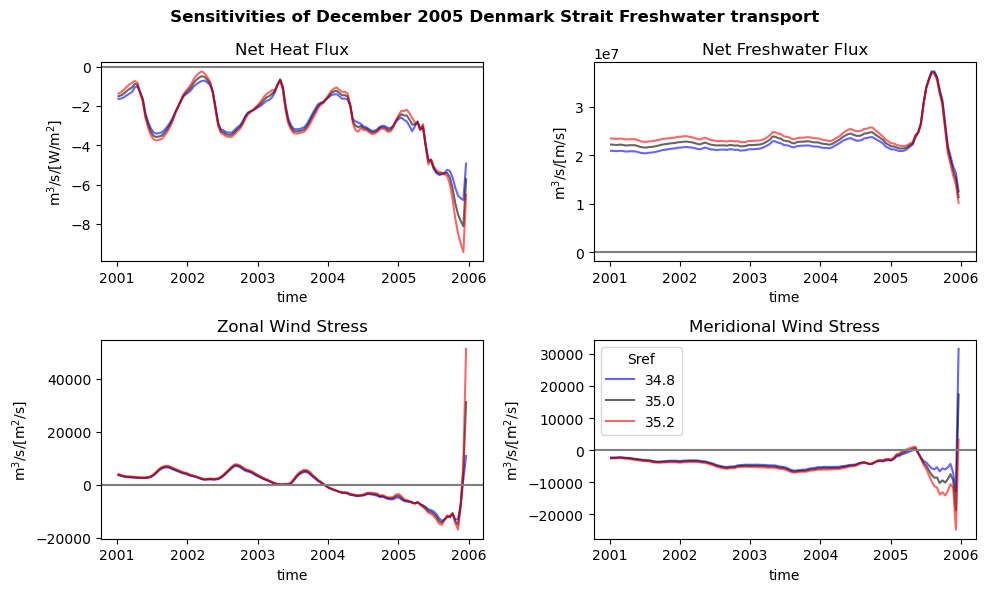

In [33]:
fig, axs = plt.subplots(ncols=2, nrows=2, figsize=[10,6])
colors=['b','k','r']

exf_units=dict(zip(['adxx_qnet','adxx_empmr','adxx_tauu','adxx_tauv'],['W/m$^2$','m/s','m$^2$/s','m$^2$/s']))
exf_labels=dict(zip(['adxx_qnet','adxx_empmr','adxx_tauu','adxx_tauv'],['Net Heat Flux','Net Freshwater Flux','Zonal Wind Stress','Meridional Wind Stress']))

for iis,sref in enumerate([34.8,35,35.2]):
    for iv,var in enumerate(['adxx_qnet','adxx_empmr','adxx_tauu','adxx_tauv']):
        ax=axs.flatten()[iv]
        ds_FWapprox[sref][var].sum(['tile','i','j']).sel(time=slice('2001-01-01',None)).plot(ax=ax,x='time',color=colors[iis],alpha=0.6)
    plt.legend(['34.8','35.0','35.2'],title='Sref')
for iv,var in enumerate(['adxx_qnet','adxx_empmr','adxx_tauu','adxx_tauv']):
    ax=axs.flatten()[iv]
    ax.set_title(exf_labels[var])
    ax.set_ylabel('m$^3$/s/[{}]'.format(exf_units[var]))
    ax.axhline(0,color='grey')
plt.suptitle('Sensitivities of December 2005 Denmark Strait Freshwater transport',fontweight='bold')
plt.tight_layout()
plt.savefig('../plots/FigC2_horflux_Dec_fwvsSref_sens.pdf',bbox_inches='tight')